In [1]:
import myhda_ur as hda

In [2]:
hdata = hda.load_scifate()

## Total RNA

### Expression-distance clusters

gene x cell expression matrix -> distance matrix -> cluster -> visualize with PCA

In [3]:
# Initialize a temporary subset object for the selected cells 
subset_cells_ = hdata[:2000, :600]  # 2000 genes x 600 cells

In [4]:
# Compute cell-cell similarity of the selected cells using normalized gene expression values 
hdata.compute_similarity(
    data=subset_cells_,
    key="X",
    kind="cell",
    method="correlation"
)

sim_cells_ = hdata.similarities["correlation_X_cell"]

Similarity "correlation_X_cell" stored! 



In [5]:
# Cluster the cells using Spectral Clustering
hdata.cluster_spectral(
        sim = sim_cells_,                                 
        kind = "cell",
        k = 6
    )

cl_spec_cells_ = hdata.clusters["spectral_k6_cell"]

Cluster "spectral_k6_cell" stored! 



In [ ]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data = subset_cells_,
    key = "X",
    kind = "cell",
    id = "exp_dist"
)

em_cells_ = hdata.embeddings["umap_cell_exp_dist"]

UMAP embedding "umap_cell_exp_dist" stored! 



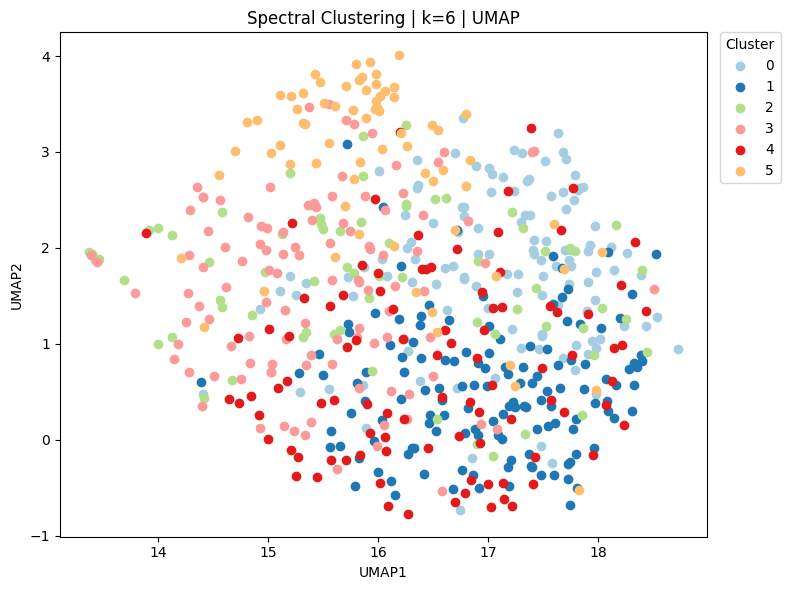

In [ ]:
# Visualize 
hda.visualize.scatter(
    cluster=cl_spec_cells_,
    embedding=em_cells_,
    title="Spectral Clustering | k=6",
    show_label=False
)

### PCA-based clusters 

gene x cell expression matrix -> PCA (cell x PC) -> distance matrix -> cluster

In [10]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=20
)

pc_matrix = hdata.layers["pca"]    

PCA matrix X x 20 PCs stored in data.layers["pca"] 



In [11]:
# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca",
    method="correlation"
)

sim_pca_cells_ = hdata.similarities["correlation_pca_cell"]   

Similarity "correlation_pca_cell" stored! 



In [12]:
# Cluster in PC space
hdata.cluster_spectral(
    sim=sim_pca_cells_,
    kind="cell",
    k=6
)

cl_pca_cells_ = hdata.clusters["spectral_k6_cell"]

Cluster "spectral_k6_cell" stored! 



In [14]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    key = "pca",
    kind = "cell",
    id = "pc20"
)

em_pca_cells_ = hdata.embeddings["umap_cell_pc20"]

UMAP embedding "umap_cell_pc20" stored! 



#### PC = 20

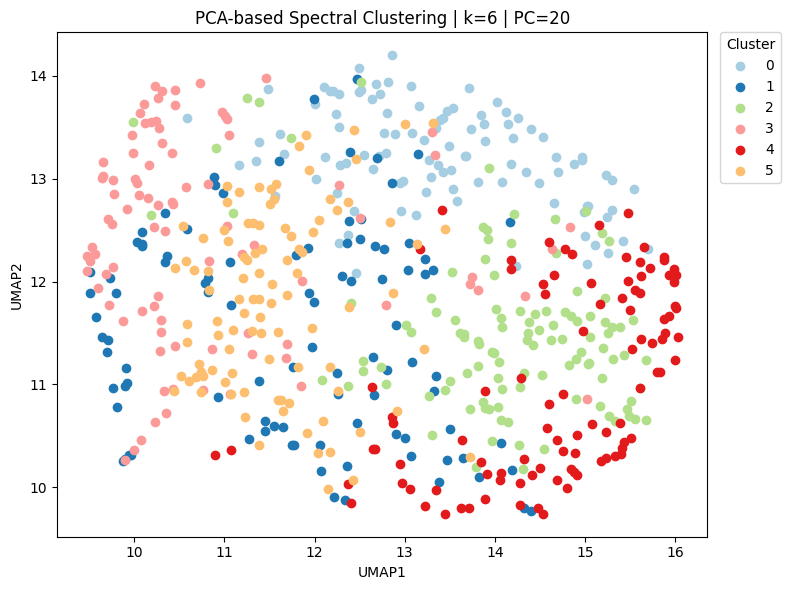

In [15]:
# Visualize 
hda.visualize.scatter(
    cluster=cl_pca_cells_,
    embedding=em_pca_cells_,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

#### PC = 5

PCA matrix X x 5 PCs stored in data.layers["pca"] 

Similarity "correlation_pca_cell" stored! 

Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc5" stored! 



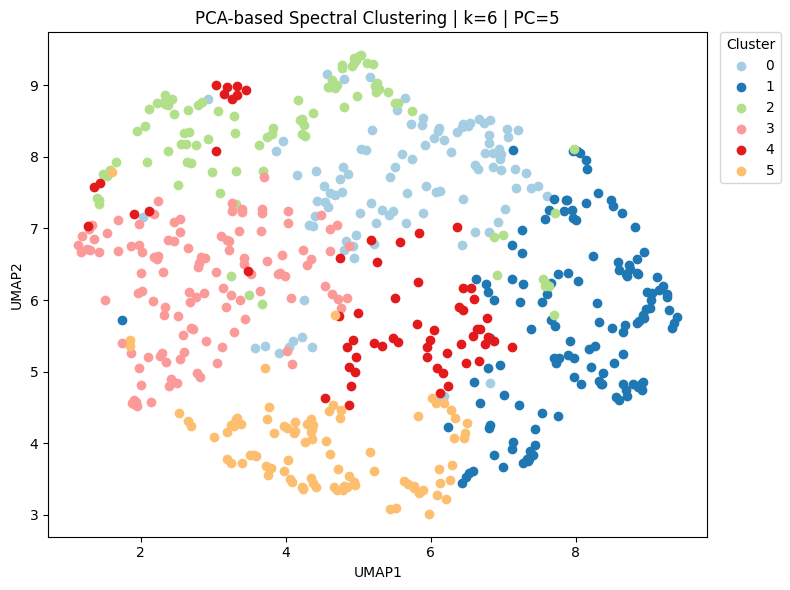

In [16]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=5
)

pc_matrix = hdata.layers["pca"]     

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca",
    method="correlation"
)

sim1 = hdata.similarities["correlation_pca_cell"]  

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim1,
    kind="cell",
    k=6
)

cl1= hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    key = "pca",
    kind = "cell",
    id = "pc5"
)

em1= hdata.embeddings["umap_cell_pc5"]

# Visualize 
hda.visualize.scatter(
    cluster=cl1,
    embedding=em1,
    title="PCA-based Spectral Clustering | k=6 | PC=5",
    show_label=False
)

#### PC = 50

PCA matrix X x 50 PCs stored in data.layers["pca"] 

Similarity "correlation_pca_cell" stored! 

Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc50" stored! 



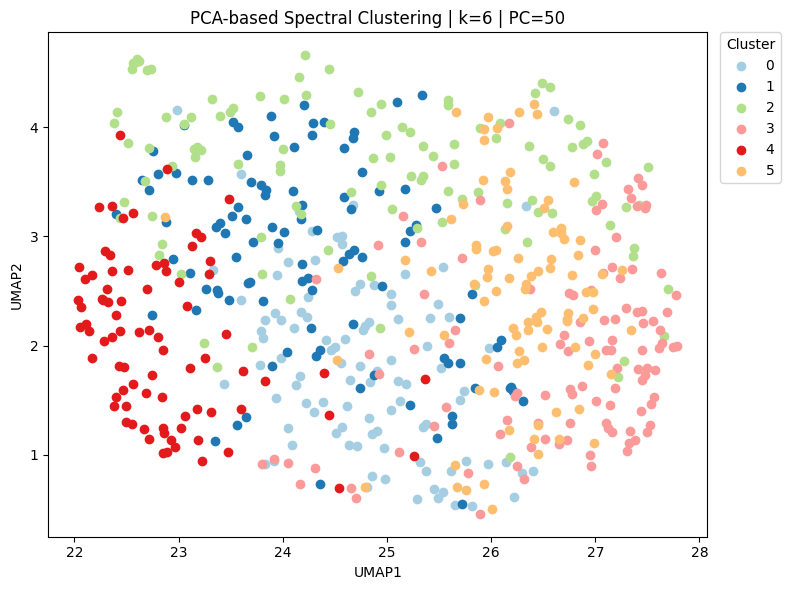

In [17]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=50
)

pc_matrix = hdata.layers["pca"]    

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca",
    method="correlation"
)

sim2 = hdata.similarities["correlation_pca_cell"]  

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim2,
    kind="cell",
    k=6
)

cl2 = hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    key = "pca",
    kind = "cell",
    id = "pc50"
)

em2= hdata.embeddings["umap_cell_pc50"] 

# Visualize 
hda.visualize.scatter(
    cluster=cl2,
    embedding=em2,
    title="PCA-based Spectral Clustering | k=6 | PC=50",
    show_label=False
)

### Compare different PC

![img1](temp/img3.jpg)

## New RNA

In [18]:
# compute New RNA from X * ntr
new_rna = subset_cells_.X.multiply(subset_cells_.layers["ntr"])

# temporarily store the new RNA matrix in subset object layers
subset_cells_.layers["new_rna"] = new_rna 

#### PC = 20

PCA matrix new_rna x 20 PCs stored in data.layers["pca"] 

Similarity "correlation_pca_cell" stored! 

Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc20" stored! 



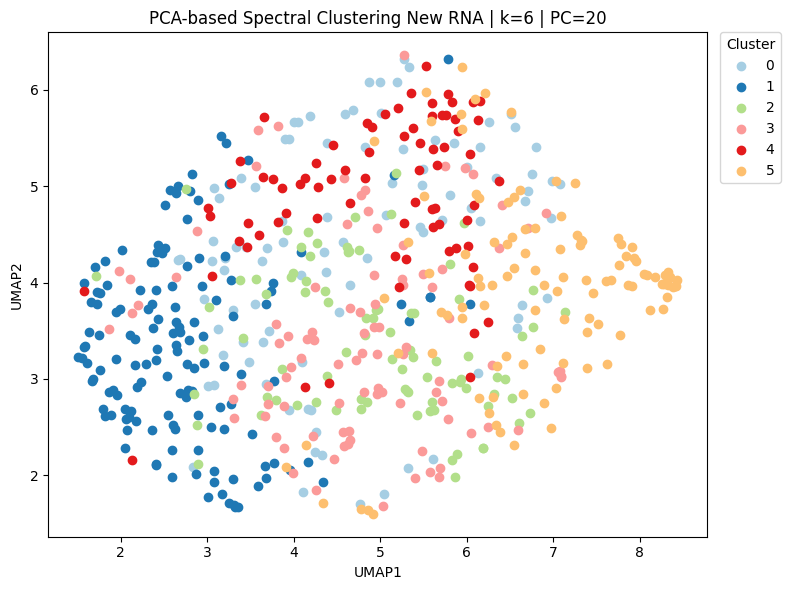

In [19]:
# PCA on new RNA
hdata.compute_PCA(
    data=subset_cells_,
    key="new_rna",      
    kind="cell",
    n_pc=20
)

pc_matrix = hdata.layers["pca"]  

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca",
    method="correlation"
)

sim_pca_newrna_ = hdata.similarities["correlation_pca_cell"]   

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim_pca_newrna_,
    kind="cell",
    k=6
)

cl_pca_newrna_ = hdata.clusters["spectral_k6_cell"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    key = "pca",
    kind = "cell",
    id = "pc20"
)

em_pca_newrna_= hdata.embeddings["umap_cell_pc20"] 

# Visualize 
hda.visualize.scatter(
    cluster=cl_pca_newrna_,
    embedding=em_pca_newrna_,
    title="PCA-based Spectral Clustering New RNA | k=6 | PC=20",
    show_label=False
)

### Compare Total RNA vs New RNA

![img2](temp/img4.jpg)